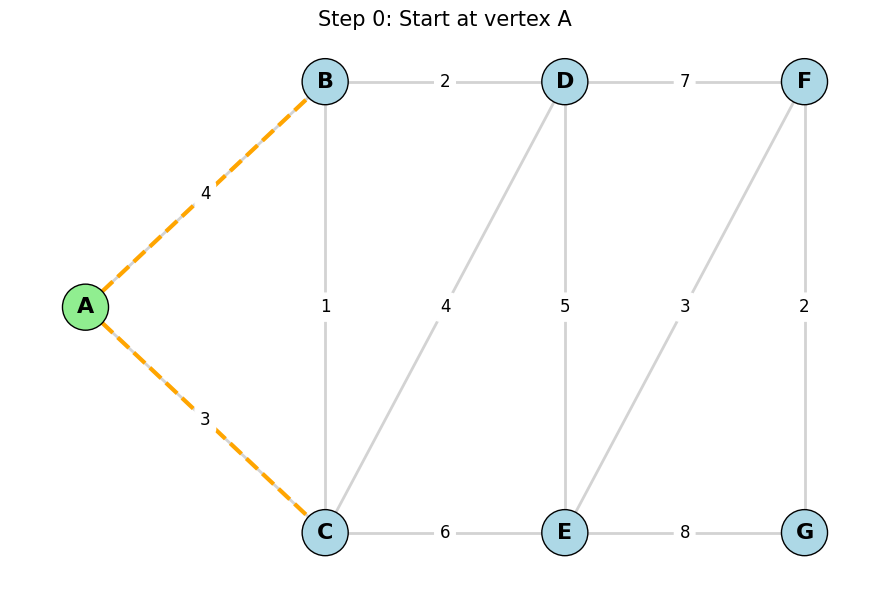

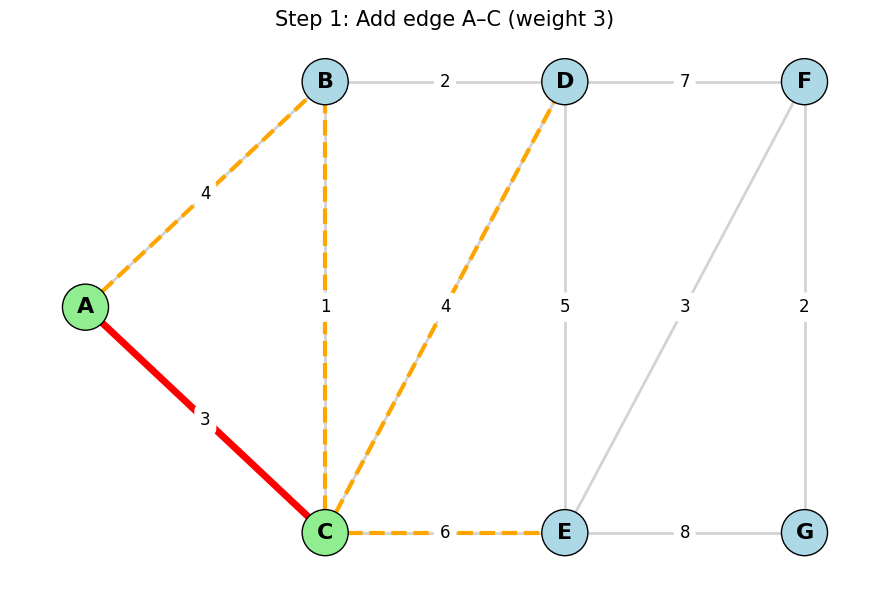

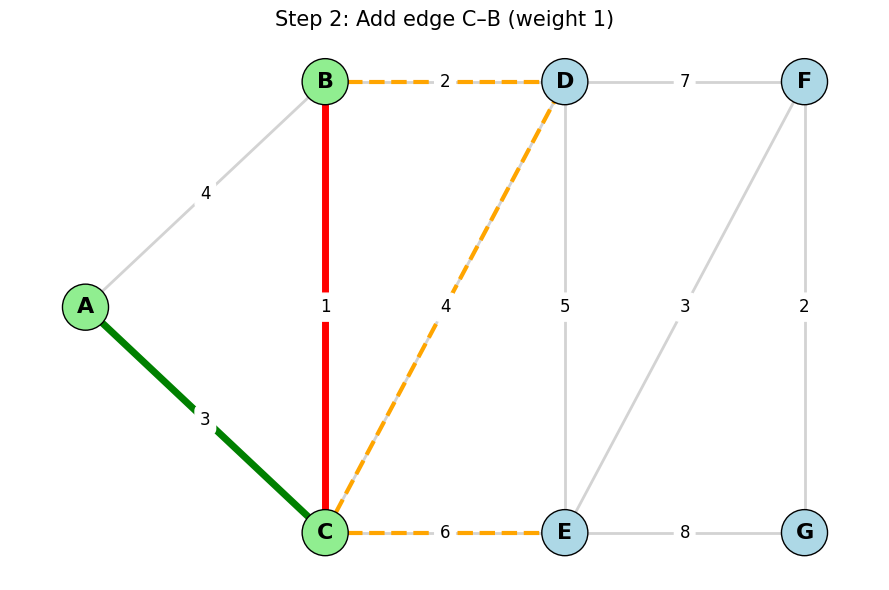

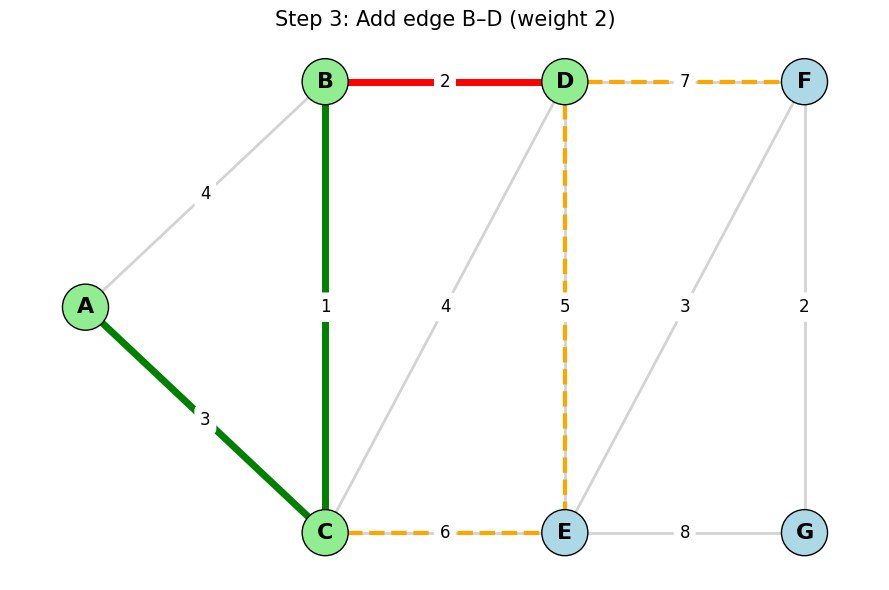

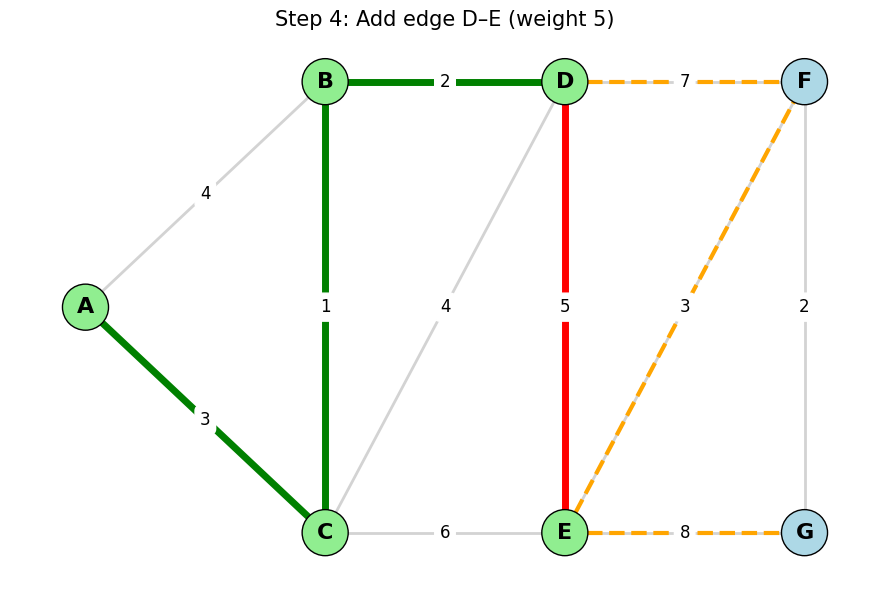

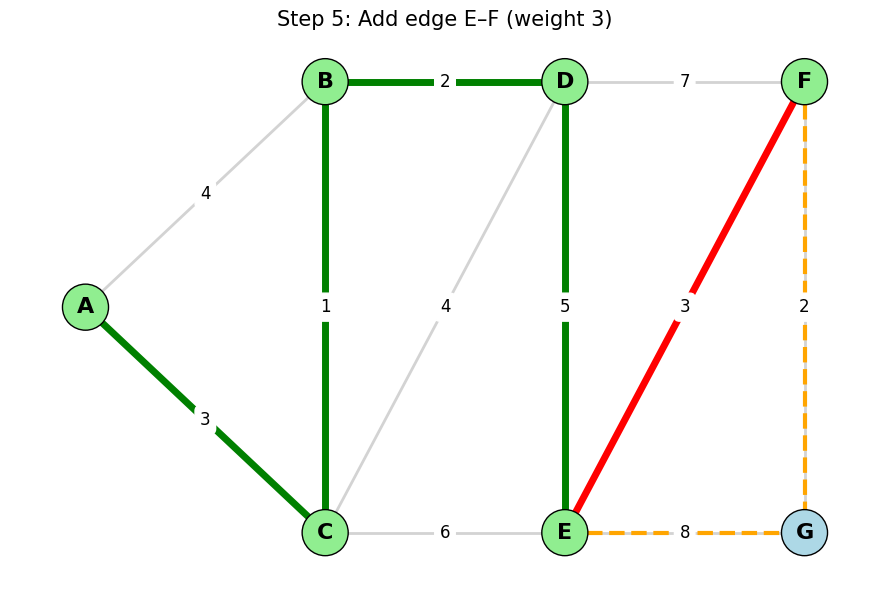

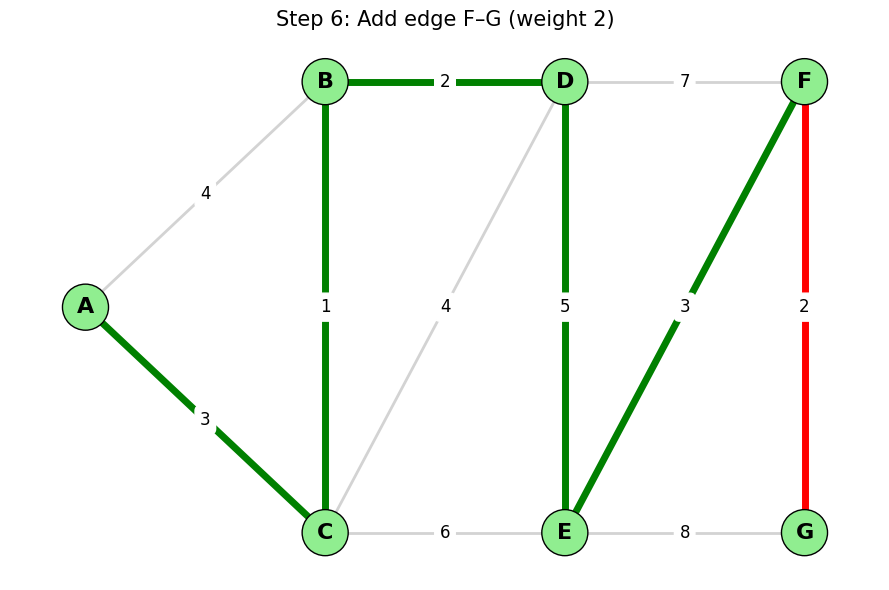

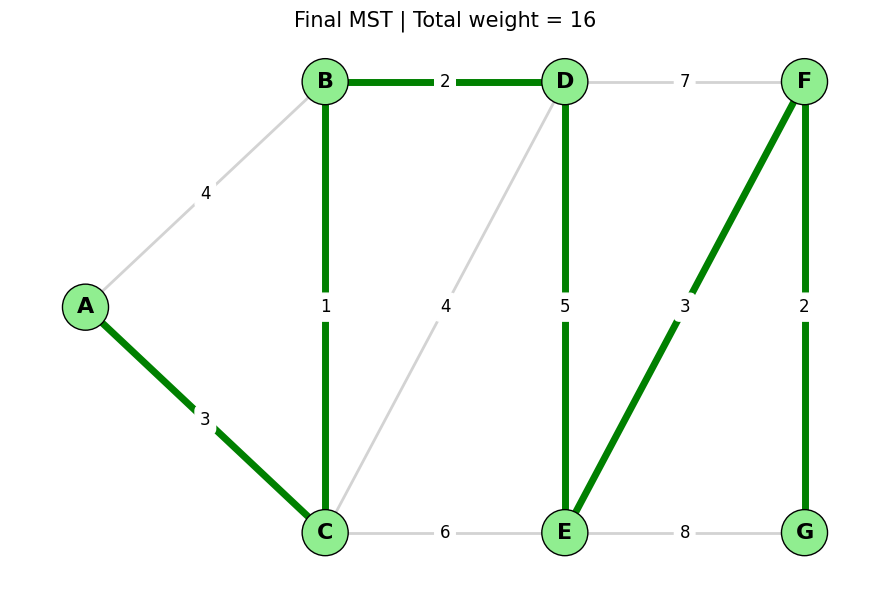


NetworkX MST weight (verification): 16.0
Our Prim's Algorithm weight: 16
Match: True


In [2]:
!pip install networkx
import heapq
import matplotlib.pyplot as plt
import networkx as nx

# 1. Create Graph
G = nx.Graph()
edges = [
    ("A", "B", 4),
    ("A", "C", 3),
    ("B", "C", 1),
    ("B", "D", 2),
    ("C", "D", 4),
    ("C", "E", 6),
    ("D", "E", 5),
    ("D", "F", 7),
    ("E", "F", 3),
    ("E", "G", 8),
    ("F", "G", 2),
]
G.add_weighted_edges_from(edges)

# Node Layout Positions
pos = {
    "A": (0, 1.5),
    "B": (2, 3),
    "C": (2, 0),
    "D": (4, 3),
    "E": (4, 0),
    "F": (6, 3),
    "G": (6, 0),
}


# 2. Graph Visualization Helper Function
def draw_graph(
    G, pos, visited, mst_edges, frontier_edges, current_edge, title
):
    plt.figure(figsize=(9, 6))

    node_colors = [
        "lightgreen" if n in visited else "lightblue" for n in G.nodes
    ]
    nx.draw_networkx_nodes(
        G, pos, node_color=node_colors, node_size=1100, edgecolors="black"
    )

    nx.draw_networkx_edges(G, pos, edge_color="lightgray", width=2)

    if frontier_edges:
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=frontier_edges,
            edge_color="orange",
            width=3,
            style="dashed",
        )

    if mst_edges:
        nx.draw_networkx_edges(
            G, pos, edgelist=mst_edges, edge_color="green", width=5
        )

    if current_edge:
        nx.draw_networkx_edges(
            G, pos, edgelist=[current_edge], edge_color="red", width=5
        )

    nx.draw_networkx_labels(G, pos, font_size=16, font_weight="bold")

    labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=labels, font_size=12, rotate=False
    )

    plt.title(title, fontsize=15)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# 3. Visual Prim's Algorithm
def prim_visual(G, start):
    visited = {start}
    mst_edges = []
    total_weight = 0

    heap = [(G[start][v]["weight"], start, v) for v in G.neighbors(start)]
    heapq.heapify(heap)

    draw_graph(
        G,
        pos,
        visited,
        mst_edges,
        [(u, v) for _, u, v in heap],
        None,
        f"Step 0: Start at vertex {start}",
    )

    step = 1
    while heap and len(visited) < len(G.nodes):
        weight, u, v = heapq.heappop(heap)

        if v in visited:
            continue

        visited.add(v)
        mst_edges.append((u, v))
        total_weight += weight

        for nbr in G.neighbors(v):
            if nbr not in visited:
                heapq.heappush(heap, (G[v][nbr]["weight"], v, nbr))

        frontier = [(a, b) for _, a, b in heap if b not in visited]

        draw_graph(
            G,
            pos,
            visited,
            mst_edges[:-1],
            frontier,
            (u, v),
            f"Step {step}: Add edge {u}–{v} (weight {weight})",
        )
        step += 1

    draw_graph(
        G,
        pos,
        visited,
        mst_edges,
        None,
        None,
        f"Final MST | Total weight = {total_weight}",
    )

    return mst_edges, total_weight


# 4. Execute Algorithm
mst_edges, total_weight = prim_visual(G, "A")

# 5. Verification
check = nx.minimum_spanning_tree(G, algorithm="prim")
check_total = check.size(weight="weight")

print("\nNetworkX MST weight (verification):", check_total)
print("Our Prim's Algorithm weight:", total_weight)
print("Match:", total_weight == check_total)